In [1]:
%load_ext autoreload
%autoreload 2

# development notebook to calculate the autocorrelation as a function of lag

In [2]:
import xarray as xr
import xskillscore as xs
import esmtools
from dask.diagnostics import ProgressBar

In [3]:
basedir_out = "/projects/SOCCOM/graemem/projects/esm4_ppe/data/processed/observations/"
localdir_obs = "NPP-RyanKeogh/NPP_MLD-EN4.2.2-0.03/"
yearstart = 1998
yearend = 2014
yearstr = "_".join([str(yearstart),str(yearend)])

In [4]:
# Load observational data
basedir_obs = "/projects/SOCCOM/datasets/"
products = ["CAFE","CbPM1","CbPM2","EPPLEY","VGPM"]
suffix_obs = "_NPP_8D_25KM_1998_2022.nc"
ds_obs = xr.Dataset()
for product in products:
    filename = product+suffix_obs
    ds_obs[product] = xr.open_dataarray(basedir_obs+localdir_obs+filename)

In [5]:
ds_obs = ds_obs.sel(time=slice(str(yearstart)+"-01-01",str(yearend)+"-12-31")).chunk({'time':'auto','lat':'auto','lon':'auto'})

In [7]:
# deseasonalize
gb = ds_obs.groupby("time.month")
ds_obs_anom = gb - gb.mean(dim='time') 

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/core/indexing.py:1446: PerformanceWarning: Slicing with an out-of-order index is generating 17 times more chunks
  return self.array[key]


In [8]:
# detrend
p = (ds_obs_anom-ds_obs_anom.mean('time')).polyfit(dim='time',deg=1)
fit = xr.polyval(ds_obs_anom.time,p)
for name in fit.data_vars:
    fit = fit.rename({name:name.split('_')[0]})
ds_obs_anom = ds_obs_anom-fit

In [9]:
# rechunk time
ds_obs_anom = ds_obs_anom.chunk({'time':-1,'lat':'auto','lon':'auto'})

In [10]:
acf = esmtools.stats.autocorr(ds_obs_anom,dim='time',nlags=12,xs_kwargs={"skipna":True})

In [32]:
with ProgressBar():
    da = acf['CAFE'].compute()

[##                                      ] | 6% Completed | 3.60 s ms

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


[##                                      ] | 6% Completed | 3.82 s

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


[##                                      ] | 6% Completed | 4.15 s

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


... (730 outputs left out)

[####################################### ] | 99% Completed | 310.31 s

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


[########################################] | 100% Completed | 310.41 s


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


In [27]:
# corr = xs.pearson_r(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'],dim='time',skipna=True)
corr = xr.corr(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'].shift({'time':-1}),dim='time')
# corr = esmtools.stats.corr(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'],dim='time',lead=0)

In [28]:
with ProgressBar():
    da = corr.compute()

[########################################] | 100% Completed | 54.79 s


In [25]:
# corr = xs.pearson_r(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'],dim='time',skipna=True)
corr = xr.corr(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'].isel(time=slice(1,None)).assign_coords({'time':shift({'time':-1}),dim='time')
# corr = esmtools.stats.corr(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'],dim='time',lead=0)

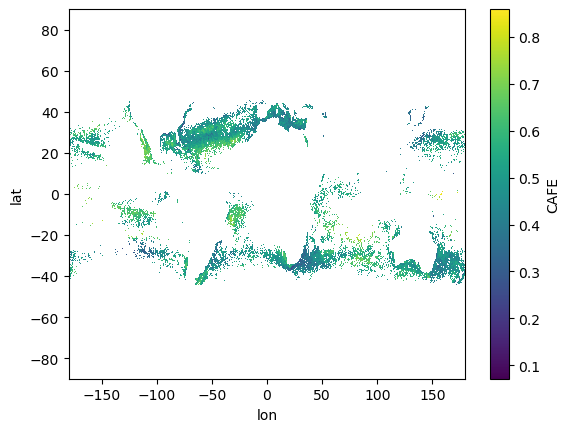

In [23]:
da.T.isel(lead=1).plot()

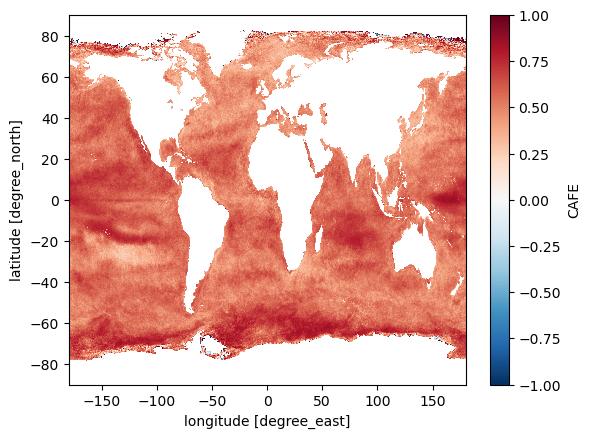

In [29]:
da.plot()

In [1]:
nlags = 3
corr = []
for i in range(nlags):
    tmp = xr.corr(ds_obs_anom['CAFE'],ds_obs_anom['CAFE'].shift({'time':-1*i}),dim='time')
    corr.append(tmp)
concat_kwargs = {'coords': 'minimal', 'compat': 'override'}
acf = xr.concat(corr,dim='lag',**concat_kwargs)

NameError: name 'xr' is not defined

In [7]:
d = None
dict(d)

TypeError: 'NoneType' object is not iterable